## Competition shear-optical

In this notebook it will be explored the competition between Jeffery rotation and intensity-gradient optical alignment (**Harmonic aproximated**) for a prolate microalga in a simple shear flow. This competition can be characterized by a dimensionless parameter
$$ \mathcal{C}_{\mathrm{orient}}=\frac{2\xi_{\mathrm{grad}}}{\beta\dot{\gamma}} $$
Where $ \xi_{\mathrm{grad}}$ is the optical aligment rate, $ \beta$ is the Bretherton parameter and $\dot{\gamma}$ is the shear rate. 

if 

$\mathcal{C}_{\mathrm{orient}}\qquad>>\qquad 1 \qquad \qquad \qquad \text{The optical alignment dominates}$

$\mathcal{C}_{\mathrm{orient}}\qquad \sim \qquad1 \qquad \qquad \qquad \text{There is a competition between the 2 effects}$

$\mathcal{C}_{\mathrm{orient}}\qquad <\qquad 1 \qquad \qquad \qquad \text{The shear starts to dominate}$

$\mathcal{C}_{\mathrm{orient}}\qquad<< \qquad1 \qquad \qquad \qquad \text{Dominates Jeffery's dynamics}$



In [3]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Path to src_Jeffery.py
src_path = Path("../Pysimulations").resolve()

if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

import src_Jeffery as jf

import tomli
from pathlib import Path

parameter_file = Path("parameters.toml")

with open(parameter_file, "rb") as f:
    params = tomli.load(f)

# ============================================================
# PARAMETERS
# ============================================================

# Particle

Length = params["particle"]["length"]
diameter = params["particle"]["diameter"]

eta = params["particle"]["eta"]

n_particle = params["particle"]["n_particle"]
n_medium = params["particle"]["n_medium"]


# Initial orientation

theta0_deg = params["initial"]["theta0_deg"]
phi0_deg = params["initial"]["phi0_deg"]


# Flow

gamma_reference = params["flow"]["gamma"]
plane = params["flow"]["plane"]


# Optical parameters

wavelength = params["optics"]["wavelength"]
w0_reference = params["optics"]["w0"]
laser_power = params["optics"]["laser_power"]

beam_axis = np.array(
    params["optics"]["beam_axis"],
    dtype=float
)


# Simulation

t0 = params["simulation"]["t0"]
tf = params["simulation"]["tf"]
n_points = params["simulation"]["n_points"]

rtol = params["simulation"]["rtol"]
atol = params["simulation"]["atol"]

In [4]:
# ============================================================
# PARTICLE GEOMETRY
# ============================================================

a = Length / 2.0
b = diameter / 2.0

Volume = (
    (4.0 / 3.0)
    * np.pi
    * a
    * b**2
)

aspect_ratio = (
    Length
    / diameter
)

beta = jf.lambda_ar(
    aspect_ratio
)

print(
    "Aspect ratio =",
    aspect_ratio
)

print(
    "beta =",
    beta
)

print(
    "Volume =",
    Volume,
    "m^3"
)

Aspect ratio = 7.142857142857143
beta = 0.9615535504119262
Volume = 1.2828170002158321e-15 m^3


In [6]:
# ============================================================
# PARTICLE OPTICAL AND HYDRODYNAMIC PARAMETERS
# ============================================================

alpha_scalar = jf.alpha(
    Volume,
    n_particle,
    n_medium
)

effective_radius = (
    diameter / 2.0
)

rotational_drag = jf.rotational_drag_sphere(
    eta,
    effective_radius
)

print(
    "alpha_scalar =",
    alpha_scalar
)

print(
    "rotational_drag =",
    rotational_drag,
    "N m s"
)

alpha_scalar = 8.483977117647844e-28
rotational_drag = 1.026920665012778e-18 N m s


The current rotational drag is evaluated using a spherical approximation. Therefore, the absolute values of $\xi_{\mathrm{grad}}$ should be interpreted as preliminary estimates for the elongated microalga.

In [7]:
# ============================================================
# PARAMETER SPACE
# ============================================================

gamma_values = np.logspace(
    -1,
    1,
    100
)

w0_values = np.linspace(
    20.0e-6,
    80.0e-6,
    120
)

print(
    "gamma range =",
    gamma_values[0],
    "to",
    gamma_values[-1],
    "1/s"
)

print(
    "w0 range =",
    w0_values[0] * 1e6,
    "to",
    w0_values[-1] * 1e6,
    "um"
)

gamma range = 0.1 to 10.0 1/s
w0 range = 20.0 to 80.0 um


In [8]:
# ============================================================
# OPTICAL ALIGNMENT RATE AS A FUNCTION OF w0
# ============================================================

xi_grad_values = []

for w0_i in w0_values:

    zR_i = jf.rayleigh_range(
        w0_i,
        wavelength
    )

    U0_i = jf.trap_depth(
        alpha_scalar,
        laser_power,
        w0_i
    )

    kx_i, ky_i, kz_i = (
        jf.harmonic_stiffness_from_gaussian(
            U0_i,
            w0_i,
            zR_i
        )
    )

    k_perp_i = (
        0.5
        * (kx_i + ky_i)
    )

    kappa_grad_i = (
        (a**2 - b**2)
        / 10.0
        * (k_perp_i - kz_i)
    )

    xi_grad_i = (
        jf.alignment_rate_from_torque(
            kappa_grad_i,
            rotational_drag
        )
    )

    xi_grad_values.append(
        xi_grad_i
    )


xi_grad_values = np.asarray(
    xi_grad_values
)

In [9]:
# ============================================================
# ORIENTATIONAL COMPETITION MAP
# ============================================================

C_orient = np.zeros(
    (
        len(w0_values),
        len(gamma_values)
    )
)

for i, xi_grad_i in enumerate(
    xi_grad_values
):

    for j, gamma_i in enumerate(
        gamma_values
    ):

        C_orient[i, j] = (
            2.0
            * xi_grad_i
            / (
                beta
                * gamma_i
            )
        )

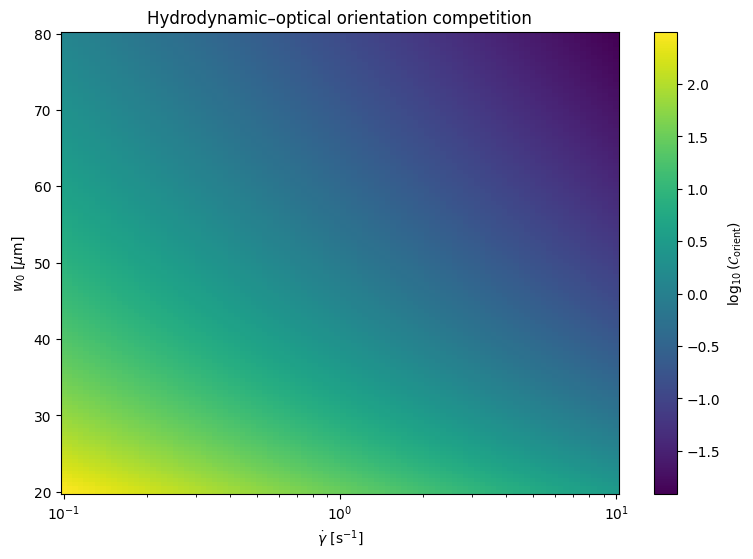

In [10]:
# ============================================================
# COMPETITION MAP
# ============================================================

Gamma, W0 = np.meshgrid(
    gamma_values,
    w0_values * 1e6
)

log_C = np.log10(
    C_orient
)

plt.figure(
    figsize=(9, 6)
)

map_plot = plt.pcolormesh(
    Gamma,
    W0,
    log_C,
    shading="auto"
)

plt.xscale("log")

cbar = plt.colorbar(
    map_plot
)

cbar.set_label(
    r"$\log_{10}(\mathcal{C}_{\mathrm{orient}})$"
)

plt.xlabel(
    r"$\dot{\gamma}$ [s$^{-1}$]"
)

plt.ylabel(
    r"$w_0$ [$\mu$m]"
)

plt.title(
    "Hydrodynamic–optical orientation competition"
)

plt.show()

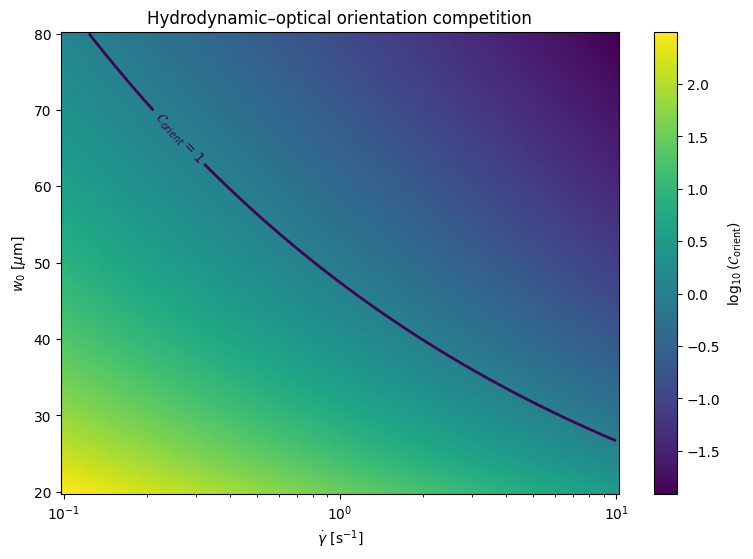

In [11]:
plt.figure(
    figsize=(9, 6)
)

map_plot = plt.pcolormesh(
    Gamma,
    W0,
    log_C,
    shading="auto"
)

plt.xscale("log")

cbar = plt.colorbar(
    map_plot
)

cbar.set_label(
    r"$\log_{10}(\mathcal{C}_{\mathrm{orient}})$"
)


# ------------------------------------------------------------
# C_orient = 1
# ------------------------------------------------------------

contour = plt.contour(
    Gamma,
    W0,
    log_C,
    levels=[0.0],
    linewidths=2.0
)

plt.clabel(
    contour,
    fmt={
        0.0: r"$\mathcal{C}_{orient}=1$"
    }
)


plt.xlabel(
    r"$\dot{\gamma}$ [s$^{-1}$]"
)

plt.ylabel(
    r"$w_0$ [$\mu$m]"
)

plt.title(
    "Hydrodynamic–optical orientation competition"
)

plt.show()

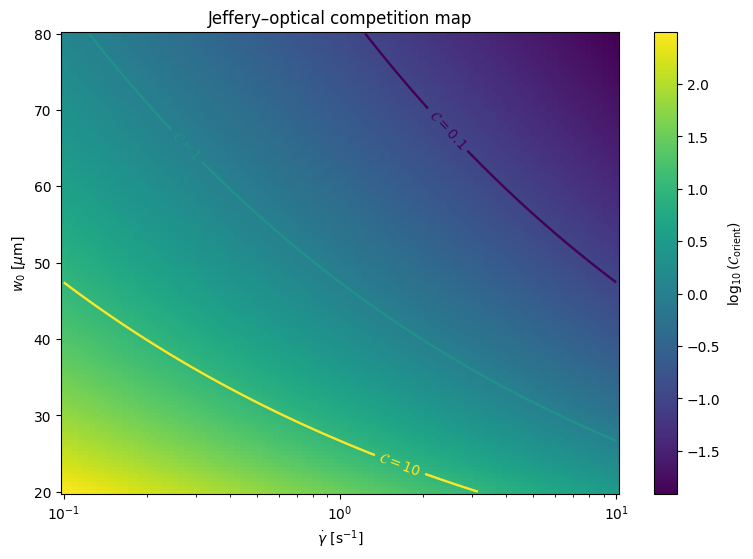

In [12]:
plt.figure(
    figsize=(9, 6)
)

map_plot = plt.pcolormesh(
    Gamma,
    W0,
    log_C,
    shading="auto"
)

plt.xscale("log")

cbar = plt.colorbar(
    map_plot
)

cbar.set_label(
    r"$\log_{10}(\mathcal{C}_{\mathrm{orient}})$"
)


contours = plt.contour(
    Gamma,
    W0,
    log_C,
    levels=[
        -1.0,
         0.0,
         1.0
    ],
    linewidths=1.7
)

plt.clabel(
    contours,
    fmt={
        -1.0: r"$\mathcal{C}=0.1$",
         0.0: r"$\mathcal{C}=1$",
         1.0: r"$\mathcal{C}=10$"
    }
)


plt.xlabel(
    r"$\dot{\gamma}$ [s$^{-1}$]"
)

plt.ylabel(
    r"$w_0$ [$\mu$m]"
)

plt.title(
    "Jeffery–optical competition map"
)

plt.show()

In [13]:
# ============================================================
# CURRENT PARAMETER POINT
# ============================================================

zR_reference = jf.rayleigh_range(
    w0_reference,
    wavelength
)

U0_reference = jf.trap_depth(
    alpha_scalar,
    laser_power,
    w0_reference
)

kx_ref, ky_ref, kz_ref = (
    jf.harmonic_stiffness_from_gaussian(
        U0_reference,
        w0_reference,
        zR_reference
    )
)

k_perp_ref = (
    0.5
    * (kx_ref + ky_ref)
)

kappa_grad_ref = (
    (a**2 - b**2)
    / 10.0
    * (k_perp_ref - kz_ref)
)

xi_grad_ref = (
    jf.alignment_rate_from_torque(
        kappa_grad_ref,
        rotational_drag
    )
)

C_orient_reference = (
    2.0
    * xi_grad_ref
    / (
        beta
        * gamma_reference
    )
)


print(
    "Current w0 =",
    w0_reference * 1e6,
    "um"
)

print(
    "Current gamma =",
    gamma_reference,
    "1/s"
)

print(
    "xi_grad =",
    xi_grad_ref,
    "1/s"
)

print(
    "C_orient =",
    C_orient_reference
)

Current w0 = 55.0 um
Current gamma = 1 1/s
xi_grad = 0.2653526083961443 1/s
C_orient = 0.5519247644241304


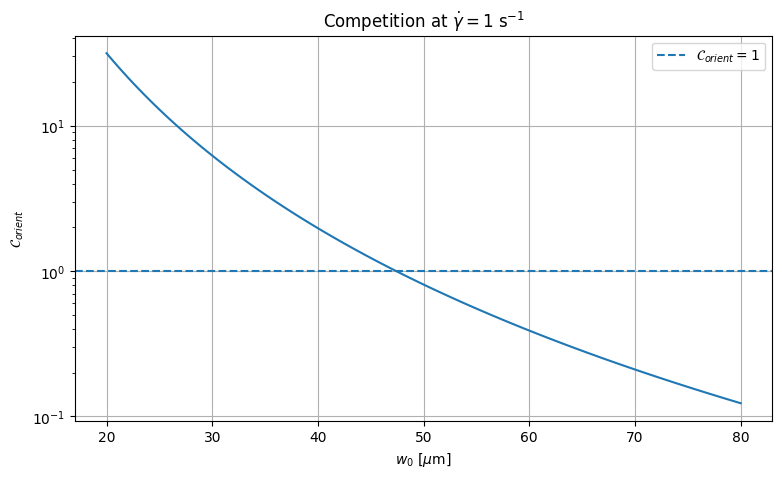

In [14]:
# ============================================================
# COMPETITION AT FIXED SHEAR
# ============================================================

C_at_reference_gamma = (
    2.0
    * xi_grad_values
    / (
        beta
        * gamma_reference
    )
)

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    w0_values * 1e6,
    C_at_reference_gamma
)

plt.axhline(
    1.0,
    linestyle="--",
    label=r"$\mathcal{C}_{orient}=1$"
)

plt.yscale("log")

plt.xlabel(
    r"$w_0$ [$\mu$m]"
)

plt.ylabel(
    r"$\mathcal{C}_{orient}$"
)

plt.title(
    rf"Competition at $\dot{{\gamma}}={gamma_reference:g}$ s$^{{-1}}$"
)

plt.grid(True)
plt.legend()

plt.show()

In [15]:
# ============================================================
# REPRESENTATIVE REGIMES
# ============================================================

target_C = [
    0.3,
    1.0,
    3.0
]

selected_indices = []

for target in target_C:

    index = np.argmin(
        np.abs(
            C_at_reference_gamma
            - target
        )
    )

    selected_indices.append(
        index
    )


for target, index in zip(
    target_C,
    selected_indices
):

    print(
        "Target C =",
        target
    )

    print(
        "w0 =",
        w0_values[index] * 1e6,
        "um"
    )

    print(
        "Actual C =",
        C_at_reference_gamma[index]
    )

    print()

Target C = 0.3
w0 = 63.8655462184874 um
Actual C = 0.30357593425593743

Target C = 1.0
w0 = 47.226890756302524 um
Actual C = 1.015240128065662

Target C = 3.0
w0 = 36.13445378151261 um
Actual C = 2.9622944573472765



In [16]:
theta0 = np.deg2rad(
    theta0_deg
)

phi0 = np.deg2rad(
    phi0_deg
)

p0 = jf.sph_to_vec(
    theta0,
    phi0
)

t_eval = np.linspace(
    t0,
    tf,
    n_points
)

In [17]:
G = jf.grad_u_simple_shear(
    gamma_reference,
    plane
)

E, W = jf.decompose_grad_u(
    G
)

In [18]:
# ============================================================
# DYNAMICS FOR REPRESENTATIVE REGIMES
# ============================================================

solutions = []

for index in selected_indices:

    xi_grad_i = (
        xi_grad_values[index]
    )

    def rhs(
        t,
        p
    ):

        p = (
            p
            / np.linalg.norm(p)
        )

        p_dot_jeffery = (
            jf.jeffery_rhs_vector(
                t,
                p,
                E,
                W,
                beta
            )
        )

        p_dot_gradient = (
            jf.uniaxial_alignment_drift(
                p,
                beam_axis,
                xi_grad_i
            )
        )

        return (
            p_dot_jeffery
            + p_dot_gradient
        )


    sol_i = solve_ivp(
        fun=rhs,
        t_span=(t0, tf),
        y0=p0,
        t_eval=t_eval,
        rtol=rtol,
        atol=atol
    )

    if not sol_i.success:
        raise RuntimeError(
            sol_i.message
        )

    solutions.append(
        sol_i
    )

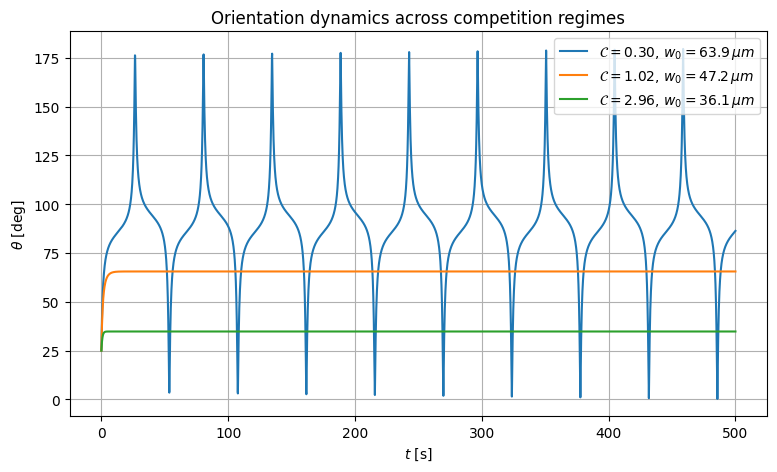

In [19]:
plt.figure(
    figsize=(9, 5)
)

for target, index, sol_i in zip(
    target_C,
    selected_indices,
    solutions
):

    P_i = jf.normalize_rows(
        sol_i.y.T
    )

    theta_i, _, _ = (
        jf.directors_to_angles(
            P_i
        )
    )

    theta_i_deg = np.rad2deg(
        theta_i
    )

    plt.plot(
        sol_i.t,
        theta_i_deg,
        label=(
            rf"$\mathcal{{C}}={C_at_reference_gamma[index]:.2f}$, "
            rf"$w_0={w0_values[index]*1e6:.1f}\,\mu m$"
        )
    )


plt.xlabel(
    r"$t$ [s]"
)

plt.ylabel(
    r"$\theta$ [deg]"
)

plt.title(
    "Orientation dynamics across competition regimes"
)

plt.grid(True)
plt.legend()

plt.show()

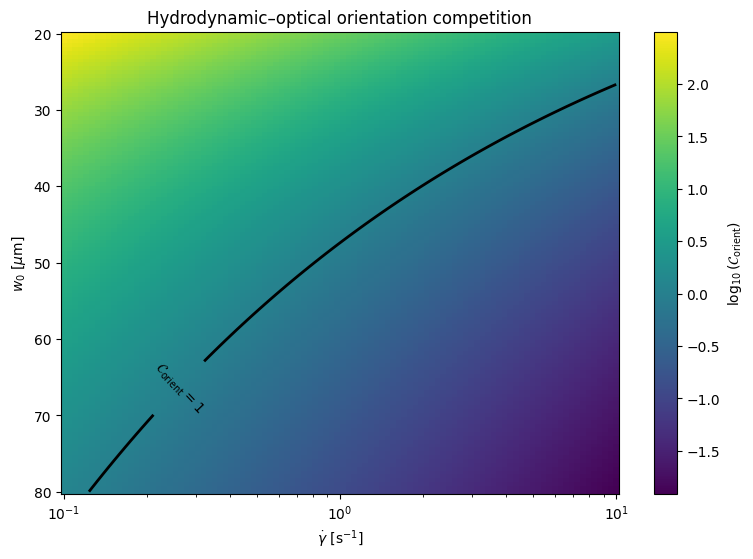

In [20]:
plt.figure(
    figsize=(9, 6)
)

map_plot = plt.pcolormesh(
    Gamma,
    W0,
    log_C,
    shading="auto"
)

plt.xscale("log")

cbar = plt.colorbar(
    map_plot
)

cbar.set_label(
    r"$\log_{10}(\mathcal{C}_{\mathrm{orient}})$"
)


# ------------------------------------------------------------
# C_orient = 1
# ------------------------------------------------------------

contour = plt.contour(
    Gamma,
    W0,
    log_C,
    levels=[0.0],
    linewidths=2.0,
    colors="black"
)

plt.clabel(
    contour,
    fmt={
        0.0: r"$\mathcal{C}_{\mathrm{orient}}=1$"
    }
)

plt.xscale("log")

# Invert y-axis
plt.gca().invert_yaxis()

plt.xlabel(
    r"$\dot{\gamma}$ [s$^{-1}$]"
)

plt.ylabel(
    r"$w_0$ [$\mu$m]"
)

plt.title(
    "Hydrodynamic–optical orientation competition"
)

plt.show()